## 1. Missioni

Una missione è composta da più righe: per identificarla si usa `ID_DG`.

Esempio: una missione ha 2 record con spese di 200 € e 300 € produce una missione da 500 €. 


In [25]:
from pathlib import Path
from decimal import Decimal
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

# Il notebook funziona partendo da progetto/ oppure da progetto/notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "config.json").exists():
    raise FileNotFoundError("Apri la cartella progetto.")

# I successivi %run trovano così gli altri notebook nella stessa cartella.
os.chdir(ROOT / "notebooks")
with (ROOT / "config.json").open(encoding="utf-8") as file:
    config = json.load(file)

uo_path = ROOT / config["uo_denominazioni_path"]
with uo_path.open(encoding="utf-8") as file:
    DENOMINAZIONE_DA_CODICE = json.load(file)

def etichetta_uo(codice):
    """Restituisce 'codice — denominazione'; se manca il nome, lascia il codice."""
    codice = str(codice)
    nome = DENOMINAZIONE_DA_CODICE.get(codice)
    return f"{codice} — {nome}" if nome else codice

#print("Esempio codice -> nome:", DENOMINAZIONE_DA_CODICE["82046"])
#print("Esempio etichetta completa:", etichetta_uo("82044"))

np.random.seed(config["seed"])
torch.manual_seed(config["seed"])
#torch.set_num_threads(2) 

device = torch.device("cpu")
if config["device"] == "auto":
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")

#print("Versioni:", "pandas", pd.__version__, "NumPy", np.__version__, "PyTorch", torch.__version__)
#print("Dispositivo:", device)
#display(pd.Series(config, name="Configurazione"))


In [26]:
csv_path = Path(config["data_path"])
if not csv_path.is_absolute():
    csv_path = ROOT / csv_path

if not csv_path.is_file():
    raise FileNotFoundError(
        f"Manca il CSV reale: {csv_path}. "
        "Aggiungi missioni_2013_2026_ALL.csv in data/, "
        "oppure modifica data_path in config.json."
    )

righe = pd.read_csv(
    csv_path,
    sep=";",
    quotechar='"',
    doublequote=True,
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False,
)

#print("Forma del CSV (righe, colonne):", righe.shape)
#print("Missioni distinte:", righe["ID_DG"].nunique())
#print("Righe identiche su tutte le colonne:", righe.duplicated().sum())
codici_csv = set(righe["ID_UO_ORIGINE"].unique())
codici_senza_denominazione = sorted(codici_csv - set(DENOMINAZIONE_DA_CODICE))
#print("Afferenze con denominazione:", len(codici_csv) - len(codici_senza_denominazione), "su", len(codici_csv))
#print("Codici senza denominazione nel file allegato:", codici_senza_denominazione)
#assert len(righe) == 294_795
#assert righe["ID_DG"].nunique() == 59_871
#assert righe.duplicated().sum() == 0  # Controllo soltanto: non eliminiamo righe.
#display(righe[["ID_DG", "ID_UO_ORIGINE", "DT_INIZIO_MIS", "IMPORTO_EURO"]].head())


In [27]:
#Per sommare denaro usiamo centesimi interi: "12,34" diventa 1234. I valori negativi mantengono il segno.
def in_centesimi(testo):
    # La virgola del CSV diventa il punto richiesto da Decimal.
    valore = Decimal(testo.replace(",", ".")) * 100
    if not valore.is_finite() or valore != valore.to_integral_value():
        raise ValueError(f"Importo non rappresentabile in centesimi: {testo}")
    return int(valore)

for colonna in ["ID_DG", "ID_UO_ORIGINE", "DT_INIZIO_MIS", "IMPORTO_EURO"]:
    assert righe[colonna].ne("").all(), f"Campo vuoto: {colonna}"

#pd.to_datetime trasforma il testo in una data. dayfirst=True indica il formato giorno/mese/anno.
righe["data_inizio"] = pd.to_datetime(
    righe["DT_INIZIO_MIS"], format="mixed", dayfirst=True, errors="raise"
)
righe["centesimi"] = righe["IMPORTO_EURO"].map(in_centesimi).astype("int64")

#print("Importi negativi nelle righe:", (righe["centesimi"] < 0).sum())
#print("Ultima data di inizio nel file:", righe["data_inizio"].max())


In [28]:
#groupby("ID_DG") raccoglie insieme le righe della stessa missione. 
gruppi = righe.groupby("ID_DG", sort=False)

#Controlliamo che afferenza e data siano uguali dentro ogni missione: solo così scegliere 'first' è corretto. Non usiamo 'NR_RIGA' come chiave di spesa.
assert gruppi["ID_UO_ORIGINE"].nunique().eq(1).all()
assert gruppi["data_inizio"].nunique().eq(1).all()

#L'aggregazione riassume ciascun gruppo: prende il primo ID_UO_ORIGINE come afferenza, la prima data_inizio e somma i centesimi. Le due assert verificano che, per ogni ID_DG, UO e data siano uniche.
missioni = gruppi.agg(
    afferenza=("ID_UO_ORIGINE", "first"),
    data_inizio=("data_inizio", "first"),
    centesimi=("centesimi", "sum"),
).reset_index()

# to_period("M") identifica il mese; to_timestamp() ne restituisce il primo giorno.
missioni["mese"] = missioni["data_inizio"].dt.to_period("M").dt.to_timestamp()
missioni["denominazione_uo"] = missioni["afferenza"].map(DENOMINAZIONE_DA_CODICE)
#assert len(missioni) == 59_871
assert int(missioni["centesimi"].sum()) == int(righe["centesimi"].sum())
#print("Missioni con importo negativo:", (missioni["centesimi"] < 0).sum())
#display(missioni.tail())


In [29]:
# Controlli sul periodo 2013–2025
nel_periodo = missioni["mese"].between("2013-01-01", "2025-12-01")
righe_nel_periodo = righe["data_inizio"].dt.year.between(2013, 2025)

#assert righe_nel_periodo.sum() == 276_679
#assert nel_periodo.sum() == 56_732
#assert int(righe.loc[righe_nel_periodo, "centesimi"].sum()) == 2_287_917_736
#assert int(missioni.loc[nel_periodo, "centesimi"].sum()) == 2_287_917_736

pd.options.display.float_format = '{:.2f}'.format
display(pd.Series({
    "righe CSV 2013–2025": int(righe_nel_periodo.sum()),
    "missioni 2013–2025": int(nel_periodo.sum()),
    "somma in euro 2013–2025": missioni.loc[nel_periodo, "centesimi"].sum() / 100,
}, name="Controlli"))

# Sono conservate tutte le missioni e tutti gli importi, inclusi quelli negativi.
# Descrizioni, ANNO_RIF, ID_PROGETTO e DURATA_GG non diventano ingressi dei modelli.


righe CSV 2013–2025         276679.00
missioni 2013–2025           56732.00
somma in euro 2013–2025   22879177.36
Name: Controlli, dtype: float64

### Afferenza - mese
Ora si passa da una riga per missione a una riga per **afferenza e mese**.

In [30]:
fine_test = pd.Timestamp(config["test_end"] + "-01")
ultimo_mese_file = missioni["mese"].max()

assert fine_test < ultimo_mese_file, "Escludere il mese finale incompleto del CSV."
selezione = missioni["mese"].between("2013-01-01", fine_test)
missioni_utili = missioni.loc[selezione].copy()

# Due aggregazioni per gruppo: numero di missioni e somma di centesimi.
osservati = missioni_utili.groupby(["afferenza", "mese"]).agg(
    conteggi=("ID_DG", "size"),
    centesimi=("centesimi", "sum"),
)

# Per ciascuna afferenza viene completato il calendario dei mesi mancanti con zero.
# Nota: il calendario parte dal primo mese in cui l'afferenza compare, quindi non aggiunge mesi precedenti alla sua prima missione.
parti = []
for codice, gruppo in missioni_utili.groupby("afferenza"):
    calendario = pd.date_range(gruppo["mese"].min(), fine_test, freq="MS")
    serie = osservati.loc[codice].reindex(calendario, fill_value=0)
    serie.index.name = "mese"
    serie = serie.reset_index()
    serie["afferenza"] = codice
    parti.append(serie)

mensili = pd.concat(parti, ignore_index=True)
mensili = mensili.sort_values(["afferenza", "mese"]).reset_index(drop=True)
mensili["denominazione_uo"] = mensili["afferenza"].map(DENOMINAZIONE_DA_CODICE)
mensili["importi"] = mensili["centesimi"] / 100  # Euro usati dai modelli.
#print("Shape tabella mensile:", mensili.shape)
#display(mensili.head(5))

In [31]:
# Controllo il numero complessivo di missioni e la somma in centesimi
assert mensili["conteggi"].sum() == len(missioni_utili)
assert int(mensili["centesimi"].sum()) == int(missioni_utili["centesimi"].sum())
assert not mensili.duplicated(["afferenza", "mese"]).any()

storico = mensili.loc[mensili["mese"] < "2026-01-01"]
#assert storico["conteggi"].sum() == 56_732
#assert int(storico["centesimi"].sum()) == 2_287_917_736

# Verifica che il primo gruppo mantenga conteggio e importo.
prima = mensili.iloc[0]
originali = missioni_utili.loc[
    (missioni_utili["afferenza"] == prima["afferenza"])
    & (missioni_utili["mese"] == prima["mese"])
]
assert prima["conteggi"] == len(originali)
assert prima["centesimi"] == originali["centesimi"].sum()

copertura_storico = mensili.groupby("afferenza").agg(
    denominazione_uo=("denominazione_uo", "first"),
    primo_mese_osservato=("mese", "min"),
    mesi=("mese", "size"),
    missioni=("conteggi", "sum"),
)
#display(copertura_storico)

Sommiamo le afferenze per osservare il totale. Mesi sull'asse orizzontale e i valori sul verticale. 

La linea verticale separa training e test. La zona arancione indica il 2026 parziale.


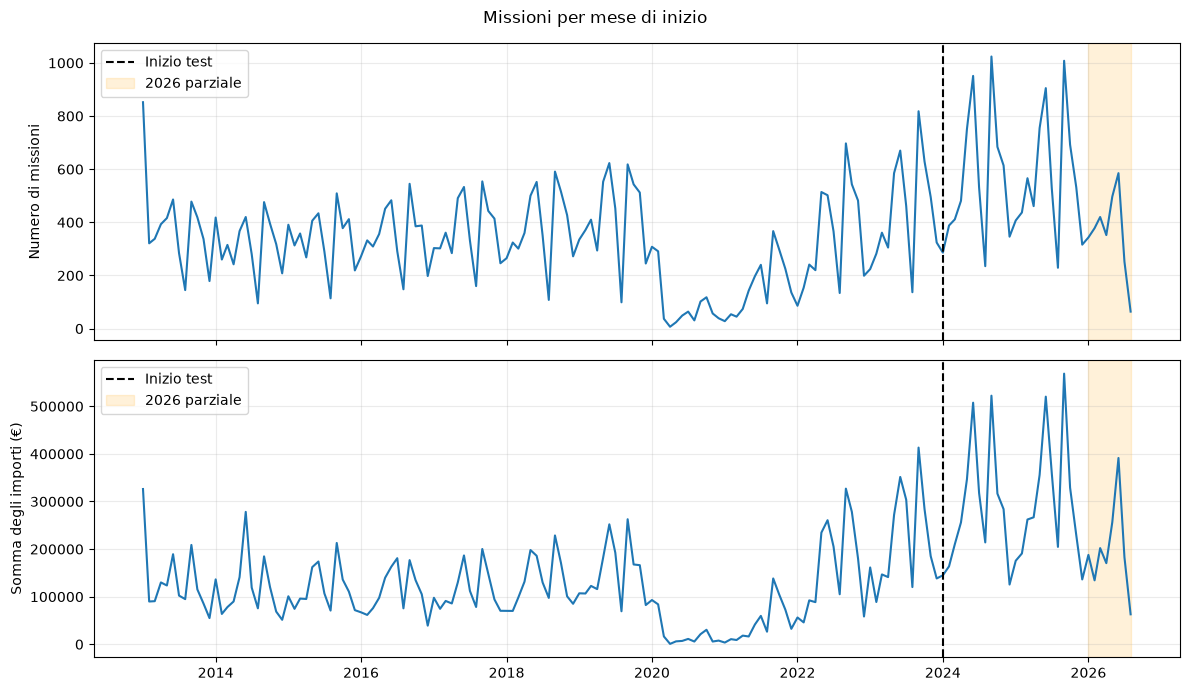

In [32]:
totali = mensili.groupby("mese")[["conteggi", "importi"]].sum()
fig, assi = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for asse, target, etichetta in zip(
    assi, ["conteggi", "importi"], ["Numero di missioni", "Somma degli importi (€)"]
):
    asse.plot(totali.index, totali[target], linewidth=1.5)
    asse.axvline(pd.Timestamp("2024-01-01"), color="black", linestyle="--", label="Inizio test")
    asse.axvspan(pd.Timestamp("2026-01-01"), fine_test, alpha=0.15, color="orange", label="2026 parziale")
    asse.set_ylabel(etichetta)
    asse.grid(alpha=0.25)
    asse.legend()

fig.suptitle("Missioni per mese di inizio")
plt.tight_layout()
plt.show()


### Stagionalità nel training

Per ogni mese dell'anno del periodo di training calcoliamo la media dei totali 2013–2023. Il grafico mostra se certi mesi hanno più missioni.

Nota: La baseline che useremo è più semplice: per prevedere gennaio 2024 faremo una copia di gennaio 2023.


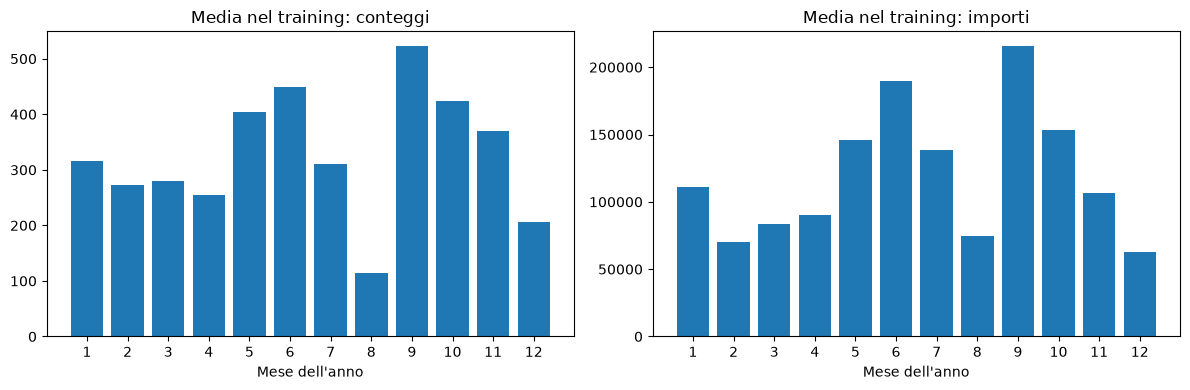

In [33]:
totali_training = totali.loc[: "2023-12-01"]
stagionalita = totali_training.groupby(totali_training.index.month).mean()

fig, assi = plt.subplots(1, 2, figsize=(12, 4))
for asse, target in zip(assi, ["conteggi", "importi"]):
    asse.bar(stagionalita.index, stagionalita[target])
    asse.set_xticks(range(1, 13))
    asse.set_xlabel("Mese dell'anno")
    asse.set_title(f"Media nel training: {target}")
plt.tight_layout()
plt.show()

#esempio_array = mensili["conteggi"].head(12).to_numpy()
#print("12 valori reali:", esempio_array)
#print("Forma dell'array:", esempio_array.shape)


In [34]:
# Lunghezza della finestra di input
LOOKBACK = config["lookback"]
fine_training = pd.Timestamp(config["train_end"] + "-01")
#assert LOOKBACK == 12
#assert fine_training == pd.Timestamp("2023-12-01")

# lag_12 è il valore di 12 mesi prima; lag_1 è quello del mese precedente.
lag_conteggi = [f"conteggi_lag_{k}" for k in range(LOOKBACK, 0, -1)]
lag_importi = [f"importi_lag_{k}" for k in range(LOOKBACK, 0, -1)]

finestre = mensili.copy()
for target in ["conteggi", "importi"]:
    for k in range(LOOKBACK, 0, -1):
        # shift(k) sposta i valori di k righe dentro la stessa afferenza.
        # La tabella è già ordinata e ha un calendario mensile continuo.
        finestre[f"{target}_lag_{k}"] = mensili.groupby("afferenza")[target].shift(k)

# I primi 12 mesi di ciascuna afferenza non hanno abbastanza passato.
finestre = finestre.dropna(subset=lag_conteggi + lag_importi).reset_index(drop=True)

train = finestre.loc[finestre["mese"] <= fine_training].copy()
test_disponibile = finestre.loc[finestre["mese"] > fine_training].copy()

# Le categorie sono solo afferenze con almeno un esempio di training.
categorie = sorted(train["afferenza"].unique())
test = test_disponibile.loc[test_disponibile["afferenza"].isin(categorie)].copy()
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

#print("Esempi di training:", len(train))
#print("Esempi di test confrontabili:", len(test))
#print("Afferenze apprese:", len(categorie))
#display(train[["afferenza", "mese"] + lag_conteggi + ["conteggi"]].head())


#Un codice apparso soltanto nel test non ha esempi da cui il modello possa imparare, lo escludiamo dal confronto.
#La tabella distingue anche i mesi senza 12 osservazioni precedenti. I totali degli errori riguardano le afferenze effettivamente valutate.
copertura = []
for anno in [2024, 2025, 2026]:
    mesi_anno = mensili.loc[mensili["mese"].dt.year == anno]
    finestre_anno = test_disponibile.loc[test_disponibile["mese"].dt.year == anno]
    valutati = test.loc[test["mese"].dt.year == anno]
    codici_esclusi = sorted(set(mesi_anno["afferenza"]) - set(valutati["afferenza"]))
    copertura.append({
        "anno": anno,
        "mesi_calendario": mesi_anno["mese"].nunique(),
        "coppie_afferenza_mese": len(mesi_anno),
        "senza_12_mesi": len(mesi_anno) - len(finestre_anno),
        "categoria_non_appresa": len(finestre_anno) - len(valutati),
        "coppie_valutate": len(valutati),
        "missioni_valutate": int(valutati["conteggi"].sum()),
        "missioni_totali": int(mesi_anno["conteggi"].sum()),
        "codici_non_valutati": ", ".join(codici_esclusi),
    })
#display(pd.DataFrame(copertura))


### Normalizzazione

Calcoliamo media e deviazione standard dai mesi di training delle afferenze ammesse. Usiamo gli stessi due numeri per gli ingressi, risposte e il test.

In [35]:
def prepara_ingressi(target):
    # La stessa preparazione serve prima ai conteggi e poi agli importi.
    # Nomi delle colonne in ordine temporale dal più lontano al più recente: lag_12, lag_11, ..., lag_1
    colonne_lag = [f"{target}_lag_{k}" for k in range(LOOKBACK, 0, -1)]
    passato = mensili.loc[
        (mensili["mese"] <= fine_training)
        & mensili["afferenza"].isin(categorie), target
    ]
    media = float(passato.mean())
    std = float(passato.std(ddof=0))
    if std == 0:
        std = 1.0  # Una serie costante non deve causare divisioni per zero.

    dati = {"media": media, "std": std}
    for nome, tabella in [("train", train), ("test", test)]:
        # Normalizza gli ingressi: i 12 mesi precedenti di ogni finestra: shape (N, 12).
        lag = tabella[colonne_lag].to_numpy(dtype=np.float32)
        sequenze = (lag - media) / std

        # Aggiunge afferenza e mese come indicatori 0/1, senza standardizzarli.
        # Stesso elenco categorie per training e test.
        codici = pd.Categorical(tabella["afferenza"], categories=categorie).codes
        assert (codici >= 0).all()
        # eye crea i vettori one-hot, omette la colonna della categoria di riferimento.
        afferenze = np.eye(len(categorie), dtype=np.float32)[codici, 1:]
        # Aggiunge il mese da prevedere
        mesi = np.eye(LOOKBACK, dtype=np.float32)[tabella["mese"].dt.month.to_numpy() - 1, 1:]
        contesto = np.concatenate([afferenze, mesi], axis=1)

        # Costruisce gli ingressi.
        # MLP e regressione ricevono tutti i valori concatenati.
        dati[f"X_{nome}"] = torch.tensor(
            np.concatenate([sequenze, contesto], axis=1), dtype=torch.float32
        )
        
        dati[f"sequenze_{nome}"] = torch.tensor(sequenze[:, :, None], dtype=torch.float32)
        dati[f"contesto_{nome}"] = torch.tensor(contesto, dtype=torch.float32)

        # Anche la risposta del mese successivo usa le stesse media e std.
        # Il vettore di risposte ha shape (N,), un valore per finestra.
        # valori: contiene una risposta per finestra. Per una finestra gennaio–dicembre 2023, la risposta è gennaio 2024
        valori = tabella[target].to_numpy(dtype=np.float32)
        # y_train e y_test contengono le risposte standardizzate. 
        # reali_train e reali_test conservano le risposte di n missioni o importi. Solo y_train partecipa all'addestramento.
        dati[f"y_{nome}"] = torch.tensor((valori - media) / std, dtype=torch.float32)
        dati[f"reali_{nome}"] = valori
        dati[f"stagionale_{nome}"] = lag[:, 0]  # Copia il valore di 12 mesi prima.
    return dati

dati_conteggi = prepara_ingressi("conteggi")
dati_importi = prepara_ingressi("importi")

#for nome, dati in [("conteggi", dati_conteggi), ("importi", dati_importi)]:
#    print(nome, "media:", round(dati["media"], 2), "std:", round(dati["std"], 2))
#    print("X training:", tuple(dati["X_train"].shape))
#    print("Risposte training:", tuple(dati["y_train"].shape))

In [36]:
assert train["mese"].max() == pd.Timestamp("2023-12-01")
assert test["mese"].min() == pd.Timestamp("2024-01-01")
assert test["mese"].max() == fine_test
# Controlla le afferenze e l'assenza di esempi condivisi
assert set(train["afferenza"]) == set(categorie)
assert set(test["afferenza"]).issubset(categorie)
assert not set(zip(train["afferenza"], train["mese"])) & set(zip(test["afferenza"], test["mese"]))

# Controlla che ogni lag contenga il mese giusto e verifica i valori passati di ogni finestra
indice_mensile = mensili.set_index(["afferenza", "mese"])
for k in range(1, 13):
    mesi_passati = finestre["mese"] - pd.DateOffset(months=k)
    assert (mesi_passati < finestre["mese"]).all()
    indici = pd.MultiIndex.from_arrays([finestre["afferenza"], mesi_passati])
    for target in ["conteggi", "importi"]:
        attesi = indice_mensile[target].reindex(indici).to_numpy()
        np.testing.assert_allclose(finestre[f"{target}_lag_{k}"], attesi)

# Controlla media, std e che la normalizzazione sia reversibile
for target, dati in [("conteggi", dati_conteggi), ("importi", dati_importi)]:
    ammessi = mensili.loc[
        (mensili["mese"] <= fine_training) & mensili["afferenza"].isin(categorie), target
    ]
    assert dati["media"] == float(ammessi.mean())
    assert dati["std"] == float(ammessi.std(ddof=0))
    ricostruiti = dati["y_test"].numpy() * dati["std"] + dati["media"]
    np.testing.assert_allclose(ricostruiti, dati["reali_test"], rtol=1e-5, atol=0.05)
    np.testing.assert_allclose(dati["stagionale_test"], test[f"{target}_lag_12"])

#print("Controlli superati: finestre e normalizzazione.")